In [66]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from functools import reduce
import calendar

In [67]:
BASE_DIR = "clean_dataset"

table_date = [
    'sales_pipeline'
]

date_columns = {
    name: ['engage_date', 'close_date']
    for name in table_date}


dfs = {}

for file in os.listdir(BASE_DIR):

    if file.endswith(".csv"):

        path = os.path.join(BASE_DIR, file)
        name = file.replace(".csv", "")

        dates = date_columns.get(name, None)

     
        df = pd.read_csv(
            path,
            parse_dates=dates
        )

        dfs[name] = df



In [68]:
df_sales_pipeline = dfs['sales_pipeline']
df_products = dfs['products']
df_account = dfs['accounts']
df_sales_pipeline_all_eng = df_sales_pipeline[~df_sales_pipeline['engage_date'].isna()]
df_sales_pipeline_Won = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Won']
df_sales_pipeline_Lost = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Lost']
df_sales_pipeline_Lost = pd.merge(df_sales_pipeline_Lost,df_products[['product','sales_price']],on ='product',how='left')
df_sales_pipeline_Lost.rename(
    columns={'sales_price': 'close_values_lost'},
    inplace=True
)
df_sales_pipeline_closed = df_sales_pipeline[~df_sales_pipeline['close_date'].isna()]
df_sales_pipeline_Pros = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Prospecting']
df_sales_pipeline_engaging = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Engaging']

In [69]:
print(f"Total Type of Products : {df_products['product'].nunique()}")
print(f"{'-'*10} Detail Product {'-'*10} ")
display(df_products)
print(f"Total product offered for opportunity : {df_sales_pipeline['product'].nunique()}")
print(f"{'-'*20} Product Summary {'-'*20}")



df_sales_pipeline_closed['duration_to_close'] = (
    df_sales_pipeline_closed['close_date'] -
    df_sales_pipeline_closed['engage_date']
).dt.days

df_sales_pipeline_Won['duration_to_win'] = (
    df_sales_pipeline_Won['close_date'] -
    df_sales_pipeline_Won['engage_date']
).dt.days



def product_summary(df, name):
    result = (
        df
        .groupby('product')
        .agg(**{
            f'total_{name}': ('product', 'count')
        })
        .reset_index()
    )

    return result



product_all = product_summary(df_sales_pipeline, 'product')
product_lost = product_summary(df_sales_pipeline_Lost, 'lost')
product_won = product_summary(df_sales_pipeline_Won, 'won')
product_eng = product_summary(df_sales_pipeline_engaging, 'engaged')
product_pros = product_summary(df_sales_pipeline_Pros, 'prospecting')



product_won_detail = (
    df_sales_pipeline_Won
    .groupby('product')
    .agg(
        total_value=('close_value', 'sum'),
        avg_duration_to_win=('duration_to_win', 'mean')
    ).round(0)
    .reset_index()
)



product_closed = (
    df_sales_pipeline_closed
    .groupby('product')
    .agg(
        avg_duration_to_close=('duration_to_close', 'mean')
    ).round(0)
    .reset_index()
)



product_sum = [
    product_all,
    product_pros,
    product_eng,
    product_won,
    product_won_detail,
    product_lost,
    product_closed
]

product_summary = reduce(
    lambda df1, df2: pd.merge(
        df1, df2,
        on='product',
        how='outer'
    ),
    product_sum
)

product_summary['conversion_rate'] = ((product_summary['total_won']/product_summary['total_product'])*100).round(0)
product_summary['win_rate'] = ((product_summary['total_won']/(product_summary['total_won']+product_summary['total_lost']))*100).round(0)
display(product_summary)



Total Type of Products : 7
---------- Detail Product ---------- 


,product,series,sales_price
0,GTX Basic,GTX,550
1,GTX Pro,GTX,4821
2,MG Special,MG,55
3,MG Advanced,MG,3393
4,GTX Plus Pro,GTX,5482
5,GTX Plus Basic,GTX,1096
6,GTK 500,GTK,26768


Total product offered for opportunity : 7
-------------------- Product Summary --------------------


,product,total_product,total_prospecting,total_engaged,total_won,total_value,avg_duration_to_win,total_lost,avg_duration_to_close,conversion_rate,win_rate
0,GTK 500,40,NaN,15,15,400612.0,64.0,10,54.0,38.0,60.0
1,GTX Basic,1866,93.0,337,915,499263.0,55.0,521,50.0,49.0,64.0
2,GTX Plus Basic,1383,74.0,258,653,705275.0,52.0,398,49.0,47.0,62.0
3,GTX Plus Pro,968,47.0,176,479,2629651.0,52.0,266,46.0,49.0,64.0
4,GTX Pro,1480,80.0,253,729,3510578.0,48.0,418,46.0,49.0,64.0
5,MG Advanced,1412,86.0,242,654,2216387.0,52.0,430,47.0,46.0,60.0
6,MG Special,1651,120.0,308,793,43768.0,51.0,430,48.0,48.0,65.0


In [96]:
display(df_sales_pipeline[df_sales_pipeline['account']!='Unidentified']
        .groupby('account')
        .agg(total_product = ('product','count'))
        .sort_values('total_product',ascending=False)
        .reset_index()
        .head(10))



def product_corsstab(df,column, name):
    Result_all = pd.crosstab(df['product'], df[column])

    Final_result = pd.DataFrame({
        f'Most Account {name}': Result_all.idxmax(axis=1),
        f'Number of {name}': Result_all.max(axis=1)
    }).reset_index()

    return Final_result

product_x_engaged = product_corsstab(df_sales_pipeline[df_sales_pipeline['account']!='Unidentified'],'account','engaged')
product_x_won = product_corsstab(df_sales_pipeline_Won,'account','Won')
product_x_lost = product_corsstab(df_sales_pipeline_Lost,'account','Lost')

product_x_account =[
    product_x_engaged,
    product_x_won,
    product_x_lost
]

product_x_account_performance = (
    reduce(
        lambda df1,df2:pd.merge(
            df1,df2,on='product',how = 'outer'
        ),product_x_account)
)

product_x_account_performance

,account,total_product
0,Hottechi,209
1,Kan-code,206
2,Konex,190
3,Condax,183
4,Dontechi,147
5,Isdom,134
6,Codehow,132
7,Singletechno,130
8,Inity,127
9,Treequote,124


,product,Most Account engaged,Number of engaged,Most Account Won,Number of Won,Most Account Lost,Number of Lost
0,GTK 500,Cheers,6,Cheers,3,Cheers,3
1,GTX Basic,Hottechi,64,Hottechi,37,Hottechi,23
2,GTX Plus Basic,Konex,37,Hottechi,20,Konex,14
3,GTX Plus Pro,Kan-code,25,Kan-code,17,Xx-zobam,10
4,GTX Pro,Kan-code,45,Kan-code,26,Kan-code,16
5,MG Advanced,Kan-code,35,Konex,22,Hottechi,17
6,MG Special,Condax,47,Condax,30,Codehow,14


beberapa product tercatat memiliki jumlah opportunity engaged terbanyak di account yang berbeda-beda, begitu juga account dengan most won dan lost yang juga berbeda-beda

In [ ]:
df_product_x_sector = (
    pd.merge(
        df_sales_pipeline,
        df_account[['account','sector']]
        ,on='account'
        ,how='outer')
)

display(
    df_product_x_sector[df_product_x_sector['account']!='Unidentified']
    .groupby('sector')
    .agg(total_product = ('product','count')).
    sort_values('total_product',ascending=False)
    .reset_index()
)


def crosstab_sector (df1,df2):
    results = (
        pd.merge(
            df1,
            df2[['account','sector']],
            on='account',
            how='outer')
    )
    return results

def resume_product (df1,df2,name):
    data = crosstab_sector(df1,df2)
    data2 = product_corsstab(data,'sector',name)
    return data2

product_x_sector_eng = resume_product(df_sales_pipeline[df_sales_pipeline['account']!='Unidentified'],df_account,'Engaged')
product_x_sector_won = resume_product(df_sales_pipeline_Won,df_account,'Won')
product_x_sector_lost = resume_product(df_sales_pipeline_Lost,df_account,'Lost')

product_x_sector = [
    product_x_sector_eng,
    product_x_sector_won,
    product_x_sector_lost
]

product_x_sector_performance = (
    reduce(
        lambda df1,df2: pd.merge(
            df1,df2, on= 'product', how = 'outer'
        ),product_x_sector
    )
)

product_x_sector_performance


,sector,total_product
0,retail,1617
1,technolgy,1305
2,medical,1208
3,software,845
4,finance,780
5,marketing,774
6,telecommunications,587
7,entertainment,536
8,services,447
9,employment,364


,product,Most Account Engaged,Number of Engaged,Most Account Won,Number of Won,Most Account Lost,Number of Lost
0,GTK 500,entertainment,9,entertainment,4,entertainment,3
1,GTX Basic,retail,333,retail,186,technolgy,101
2,GTX Plus Basic,retail,252,retail,126,retail,78
3,GTX Plus Pro,retail,197,retail,92,retail,56
4,GTX Pro,retail,276,retail,137,retail,79
5,MG Advanced,retail,258,retail,121,retail,82
6,MG Special,retail,298,retail,135,retail,92


In [74]:
products = df_products['product'].unique()

def monthly_product(df, product_name, date_column, name):
    data = (
        df[df['product'] == product_name]
        .groupby([
            df[date_column].dt.year.rename('year'),
            df[date_column].dt.month.rename('month')
        ])
        .agg(**{
            f'total_{name}': ('product', 'count')
        })
        .reset_index()
    )
    return data


product_summary = {}

for product in products:

    data = {
        "Engaged": (df_sales_pipeline_all_eng, 'engage_date', 'engaged'),
        "Won": (df_sales_pipeline_Won, 'close_date', 'won'),
        "Lost": (df_sales_pipeline_Lost, 'close_date', 'lost'),
    }

    results = []

    for stage, (df, date, name) in data.items():
        result = monthly_product(df, product, date, name)
        results.append(result)

    final_result = results[0]

    for result in results[1:]:
        final_result = pd.merge(
            final_result,
            result,
            on=['year', 'month'],
            how='outer'
        )

    product_summary[product] = (
        final_result
        .sort_values(['year', 'month'])
        .fillna(0)
        .reset_index(drop=True)
    )


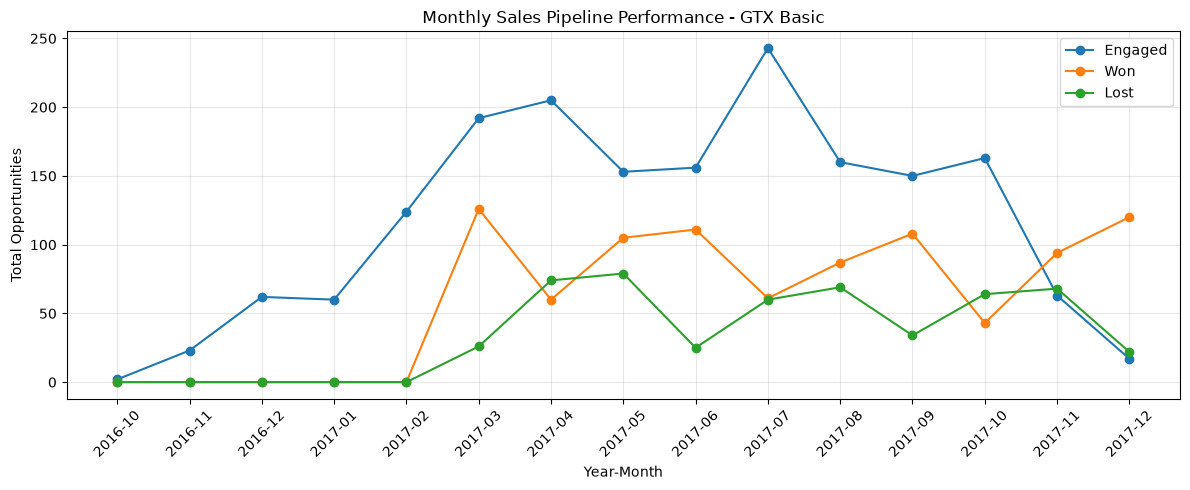

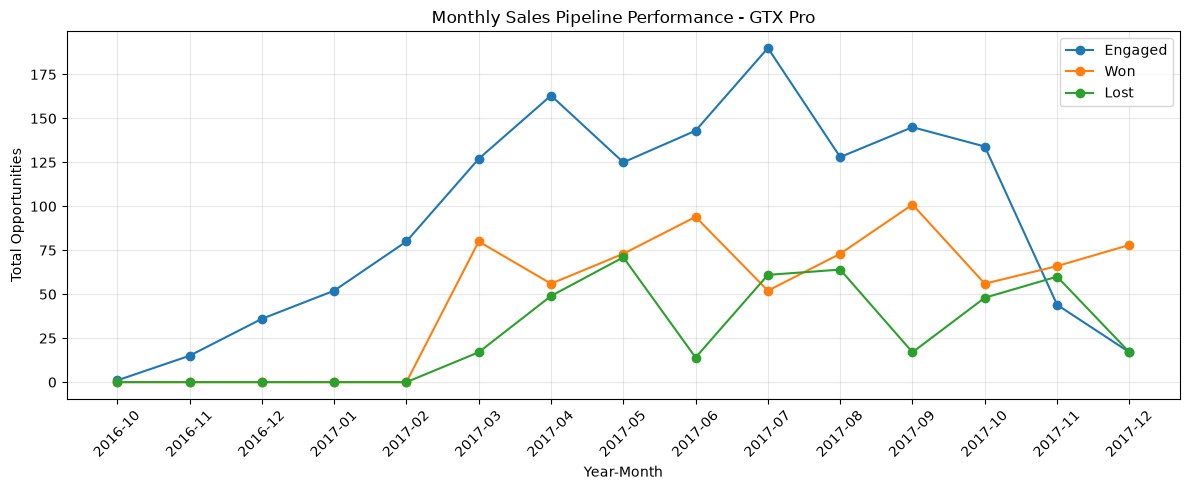

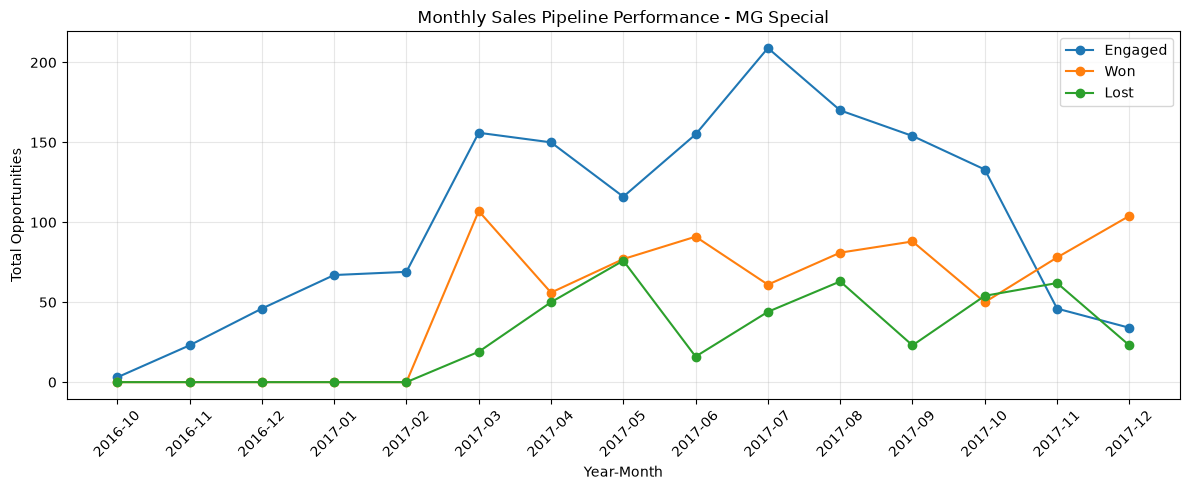

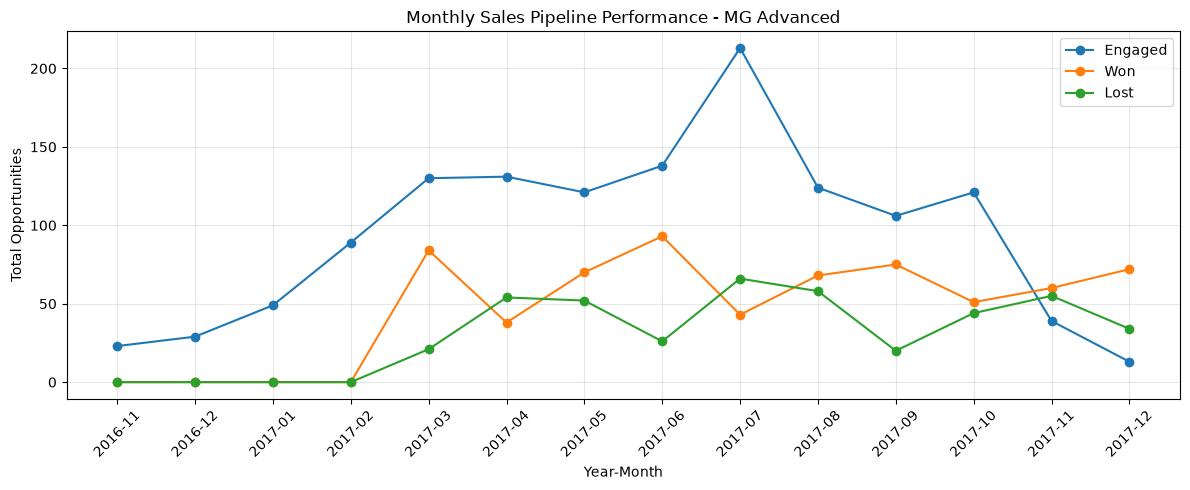

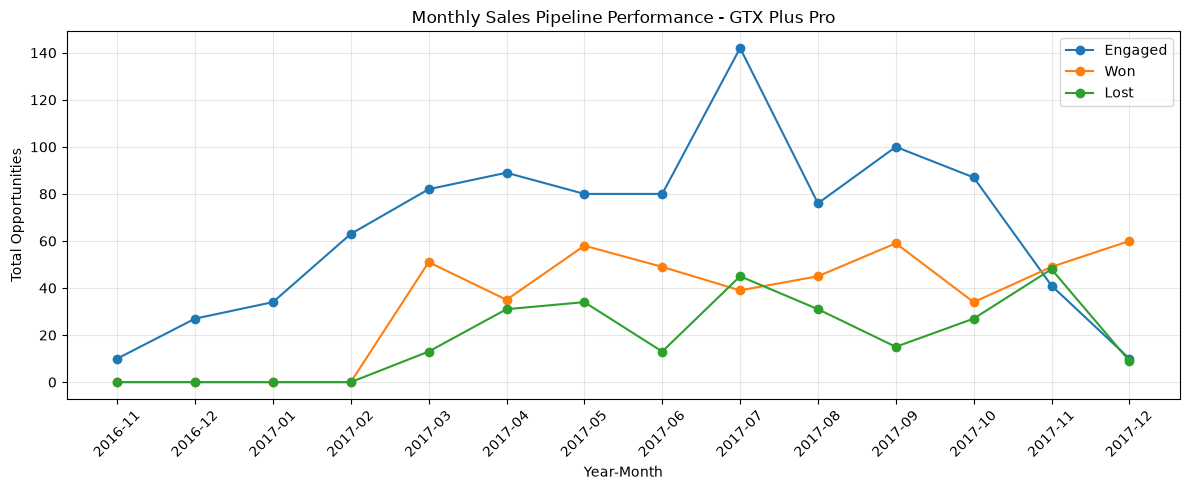

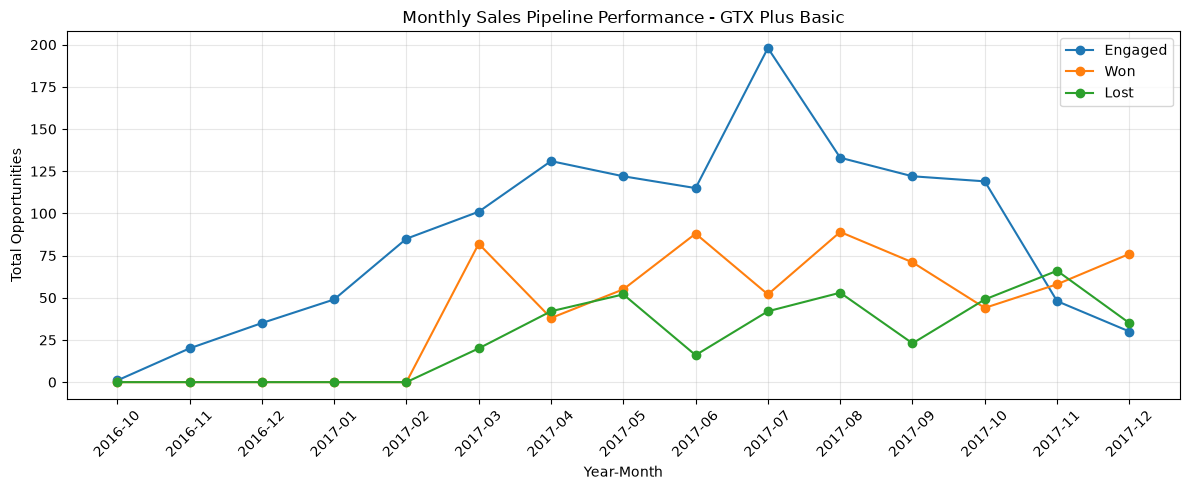

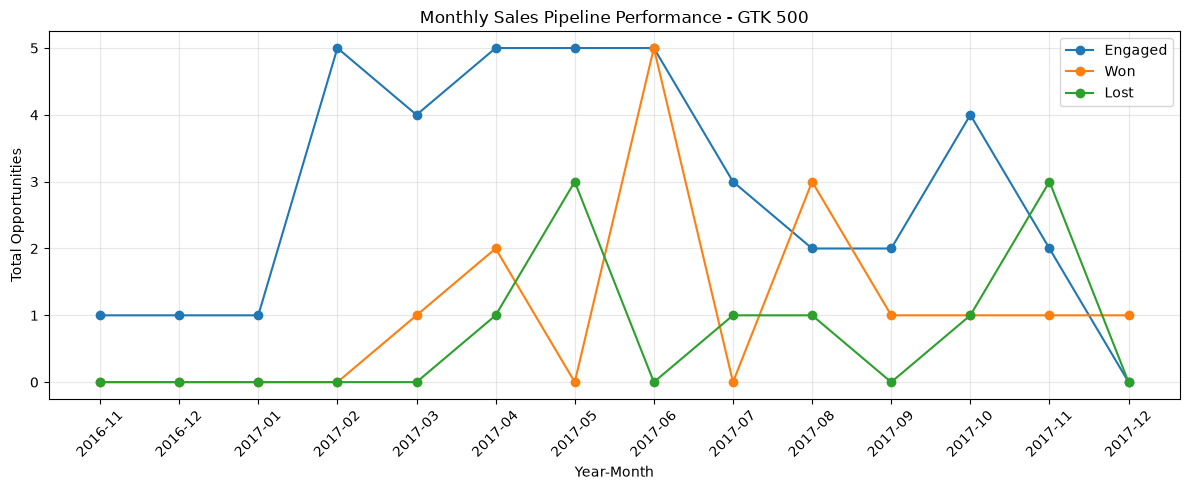

In [75]:
for product, result in product_summary.items():

    df_plot = result.copy()

   
    df_plot['year_month'] = (
        pd.to_datetime(
            df_plot[['year', 'month']].assign(day=1)
        ).dt.strftime('%Y-%m')
    )

    
    plt.figure(figsize=(12, 5))

    plt.plot(
        df_plot['year_month'],
        df_plot['total_engaged'],
        marker='o',
        label='Engaged'
    )

    plt.plot(
        df_plot['year_month'],
        df_plot['total_won'],
        marker='o',
        label='Won'
    )

    plt.plot(
        df_plot['year_month'],
        df_plot['total_lost'],
        marker='o',
        label='Lost'
    )

    plt.title(f'Monthly Sales Pipeline Performance - {product}')
    plt.xlabel('Year-Month')
    plt.ylabel('Total Opportunities')

    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.show()